# The external yardstick: the deployed engine vs cloudict

## Goal

Play the deployed engine — alpha-beta + quiescence + forward pruning + the GA champion
weights + the opening book, at its deployment depth 3, the exact configuration of
`dist/main` — against **cloudict**, the C++ Connect6 engine by Hao Cui, Liang Li, Ruijian
Wang and Siran Lin (2008-2013): gold medal at the 16th Computer Olympiad (2011) and at the
14th (2009, as Bit), and the engine whose protocol and architecture this coursework
descends from. The prebuilt snapshots in the Connect6GUI project's `engines/` folder are
x86_64 binaries that current macOS refuses to run, so `benchmarks/cloudict/` vendors the
upstream BSD-licensed source (github.com/lang010/cloudict); the setup cell compiles it
natively if the binary is missing.

Both engines play as their authors shipped them: cloudict at its default depth 6 with the
VCF threat search armed (`patterns.in`), ours at the deployment depth 3 with the champion
weights. Each runs as a subprocess speaking the shared text protocol; the notebook referee
relays moves between them and mirrors the board with the engine package's own rules
(`connect6.board`) to declare the winner.

Both engines are deterministic — cloudict seeds nothing, our search is exact — so one game
per color assignment is the complete result set, not a sample. Winners, plies, moves, node
counts and the book/VCF flags reproduce exactly run to run; only wall times vary.

## Expected behaviour

cloudict wins both games: as black in 15 plies, as white in 14 — its VCF search announces
the forced win by ply 10-11 and closes it out instantly, while its early depth-6 moves cost
27-49 s and 280,000-600,000 nodes. Ours never searches more than ~19,000 nodes or spends
more than ~7 s on a move, answers exactly one move from the book (the IIKK reply in game
1) — and loses both games. Runtime ~4 minutes; the referee allows 900 s per move.

In [1]:
import os
import queue
import re
import shutil
import subprocess
import sys
import tempfile
import threading
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tuning" / "default.json").is_file())
os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "winner.json")

from connect6.board import check_game_end, init_board, make_move
from connect6.defines import GRID_NUM, Color, GameResult
from connect6.protocol import msg2move

CLOUDICT = ROOT / "benchmarks" / "cloudict"
CLOUDICT_BIN = CLOUDICT / "gameEngine"

if not CLOUDICT_BIN.is_file():
    subprocess.run(["make"], cwd=CLOUDICT, check=True)
print(f"weights pinned to {os.environ['WEIGHTS_FILE']} (the shipped champion)")
print(f"cloudict binary: {'present' if CLOUDICT_BIN.is_file() else 'MISSING'} at {CLOUDICT_BIN}")

weights pinned to /Users/e.butovka/Documents/MyProjects/Connect6Engine/tuning/winner.json (the shipped champion)
cloudict binary: present at /Users/e.butovka/Documents/MyProjects/Connect6Engine/benchmarks/cloudict/gameEngine


## The referee

The referee speaks the shared protocol to both processes: `new black` makes an engine
auto-play the center opening `JJ`; every later reply arrives as `move XXXX`; each move is
relayed to the opponent with `move XXXX`, and the mirrored board (`connect6.board`) calls
wins and the 60-ply draw cap. A reader thread per engine feeds a queue, so a stuck engine
surfaces as a loud timeout instead of a silent hang — and every read is driven by the
flushed replies themselves, because both engines print their startup banners unflushed (a
pipe-proto subtlety). Stats lines are parsed per engine: ours reports
`Search Time/Node/Score` or `Book:`, cloudict reports `VCF time/VCF node/AB Time/Node/Score`
— and `Win by VCF.` when its threat search has taken over.

In [2]:
MOVE_RE = re.compile(r"^move ([A-S]{2,4})\s*$")
NAME_RE = re.compile(r"^name (.+)$")
SCORE_RE = re.compile(r"^Score\s*:\s*(-?[\d.]+)")
NODE_RE = re.compile(r"^Node\s*:\s*(\d+)")
TIME_RE = re.compile(r"^(?:Search Time|AB Time)\s*:\s*([\d.]+)")
VCF_TIME_RE = re.compile(r"^VCF time\s*:\s*([\d.]+)")
VCF_NODE_RE = re.compile(r"^VCF node\s*:\s*(\d+)")


class Engine:
    def __init__(self, proc, tag):
        self.proc = proc
        self.tag = tag
        self.name = None
        self.lines = queue.Queue()
        threading.Thread(target=self._reader, daemon=True).start()
        self.cmd("name")

    def _reader(self):
        for line in self.proc.stdout:
            self.lines.put(line.rstrip("\n"))

    def _next_line(self, timeout):
        try:
            return self.lines.get(timeout=timeout)
        except queue.Empty:
            raise TimeoutError(f"{self.tag}: no reply within {timeout} s") from None

    def cmd(self, line):
        self.proc.stdin.write(line + "\n")
        self.proc.stdin.flush()

    def read_reply(self, timeout):
        lines, move = [], None
        while move is None:
            line = self._next_line(timeout)
            lines.append(line)
            m = NAME_RE.match(line)
            if m:
                self.name = m.group(1).strip()
            m = MOVE_RE.match(line)
            if m:
                move = m.group(1)
        return move, lines

    def close(self):
        try:
            self.cmd("exit")
            self.proc.stdin.close()
        except Exception:
            pass
        try:
            self.proc.wait(timeout=5)
        except Exception:
            self.proc.kill()


def stats_from(lines):
    stats = {}
    for line in lines:
        m = SCORE_RE.match(line)
        if m:
            stats["score"] = float(m.group(1))
        m = NODE_RE.match(line)
        if m:
            stats["nodes"] = int(m.group(1))
        m = TIME_RE.match(line)
        if m:
            stats["time"] = float(m.group(1))
        m = VCF_TIME_RE.match(line)
        if m:
            stats["vcf_time"] = float(m.group(1))
        m = VCF_NODE_RE.match(line)
        if m:
            stats["vcf_nodes"] = int(m.group(1))
        if line.startswith("Book:"):
            stats["book"] = True
        if line.startswith("Win by VCF"):
            stats["vcf_win"] = True
    return stats


def spawn_ours():
    proc = subprocess.Popen(
        [sys.executable, str(ROOT / "main.py")],
        stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.DEVNULL,
        text=True, bufsize=1, cwd=ROOT,
    )
    return Engine(proc, "ours")


def spawn_cloudict(workdir):
    proc = subprocess.Popen(
        [str(CLOUDICT_BIN)],
        stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.DEVNULL,
        text=True, bufsize=1, cwd=workdir,
    )
    return Engine(proc, "cloudict")


def play_game(black, white, deadline_s=900, max_plies=60):
    board = [[0] * GRID_NUM for _ in range(GRID_NUM)]
    init_board(board)
    moves = []
    black.cmd("new black")
    first, _ = black.read_reply(deadline_s)
    make_move(board, msg2move(first), Color.BLACK)
    moves.append({"ply": 1, "color": "black", "engine": black.tag, "msg": first})
    white.cmd("new white")
    for engine in (black, white):
        engine.cmd("depth 3" if engine.tag == "ours" else "depth 6")
    cur, other, cur_color = white, black, Color.WHITE
    ply, winner = 1, None
    while ply < max_plies:
        start = time.perf_counter()
        cur.cmd(f"move {moves[-1]['msg']}")
        reply, lines = cur.read_reply(deadline_s)
        wall = time.perf_counter() - start
        ply += 1
        color = "black" if cur_color is Color.BLACK else "white"
        record = {"ply": ply, "color": color, "engine": cur.tag, "msg": reply, "wall": round(wall, 3)}
        record.update(stats_from(lines))
        moves.append(record)
        move = msg2move(reply)
        make_move(board, move, cur_color)
        end = check_game_end(board, move)
        if end == GameResult.WIN:
            winner = color
            break
        if end == GameResult.DRAW:
            winner = "draw"
            break
        cur, other = other, cur
        cur_color = Color.BLACK if cur_color is Color.WHITE else Color.WHITE
    return {"black": black.tag, "white": white.tag, "winner": winner, "plies": ply, "moves": moves}

## The games

Two games, both color assignments — the complete fixture for two deterministic engines.
Per-move lines show what each side paid: node counts for searched moves, `book` for the
opening-book answer, `VCF` for the forced-win finisher.

In [3]:
games = []
with tempfile.TemporaryDirectory() as td:
    shutil.copy(CLOUDICT_BIN, Path(td) / "gameEngine")
    shutil.copy(CLOUDICT / "patterns.in", Path(td) / "patterns.in")
    for black_tag, white_tag in (("cloudict", "ours"), ("ours", "cloudict")):
        engines = {"ours": spawn_ours(), "cloudict": spawn_cloudict(td)}
        start = time.perf_counter()
        record = play_game(engines[black_tag], engines[white_tag])
        record["duration_s"] = round(time.perf_counter() - start, 1)
        record["black_name"] = engines[black_tag].name
        record["white_name"] = engines[white_tag].name
        games.append(record)
        print(f"== game {len(games)}: {black_tag} (black) vs {white_tag} (white) ==")
        for rec in record["moves"]:
            if "book" in rec:
                extra = "book"
            elif "nodes" in rec:
                extra = f"{rec['time']:.2f} s, {rec['nodes']} nodes"
            elif rec["ply"] == 1:
                extra = "the center opening"
            else:
                extra = f"VCF ({rec.get('vcf_time', 0):.3f} s)"
            print(f"  ply {rec['ply']:2d} {rec['color']:5s} {rec['engine']:8s}: {rec['msg']:<6s} {extra}")
        outcome = "draw" if record["winner"] == "draw" else f"{record['winner']} wins"
        print(f"  -> {outcome} in {record['plies']} plies, {record['duration_s']} s")
        for engine in engines.values():
            engine.close()

== game 1: cloudict (black) vs ours (white) ==
  ply  1 black cloudict: JJ     the center opening
  ply  2 white ours    : IIKK   book
  ply  3 black cloudict: LJJH   46.44 s, 604211 nodes
  ply  4 white ours    : KIKJ   0.61 s, 2027 nodes
  ply  5 black cloudict: KHJI   6.29 s, 81197 nodes
  ply  6 white ours    : JKLK   0.98 s, 3214 nodes
  ply  7 black cloudict: HKIJ   11.33 s, 109776 nodes
  ply  8 white ours    : LGGL   0.61 s, 1637 nodes
  ply  9 black cloudict: IHJG   12.94 s, 153739 nodes
  ply 10 white ours    : JFLH   2.74 s, 6760 nodes
  ply 11 black cloudict: KFHI   VCF (0.010 s)
  ply 12 white ours    : GJLE   1.81 s, 4387 nodes
  ply 13 black cloudict: HHHJ   VCF (0.000 s)
  ply 14 white ours    : HGHF   0.04 s, 112 nodes
  ply 15 black cloudict: FHGH   VCF (0.004 s)
  -> black wins in 15 plies, 86.8 s


== game 2: ours (black) vs cloudict (white) ==
  ply  1 black ours    : JJ     the center opening
  ply  2 white cloudict: IJJI   35.98 s, 483169 nodes
  ply  3 black ours    : HKII   0.25 s, 1415 nodes
  ply  4 white cloudict: KKKJ   25.79 s, 287863 nodes
  ply  5 black ours    : KIIK   0.45 s, 1557 nodes
  ply  6 white cloudict: LKHL   14.43 s, 181632 nodes
  ply  7 black ours    : IHGK   0.79 s, 2535 nodes
  ply  8 white cloudict: MLKL   10.32 s, 112558 nodes
  ply  9 black ours    : NMHH   6.50 s, 19197 nodes
  ply 10 white cloudict: NLLL   VCF (0.096 s)
  ply 11 black ours    : JLOL   1.83 s, 4584 nodes
  ply 12 white cloudict: INJM   VCF (0.000 s)
  ply 13 black ours    : MJNI   1.78 s, 4219 nodes
  ply 14 white cloudict: GPHO   VCF (0.004 s)
  -> white wins in 14 plies, 98.9 s


## Validation

Both games are deterministic end to end, so the cell below asserts the complete record:
outcomes, winners, plies, every move, every node count, the lone book hit, the VCF-win ply
pattern, and the engine names — everything except wall time.

In [4]:
game1, game2 = games

assert game1["black"] == "cloudict" and game1["white"] == "ours"
assert game1["winner"] == "black" and game1["plies"] == 15
assert game2["black"] == "ours" and game2["white"] == "cloudict"
assert game2["winner"] == "white" and game2["plies"] == 14

SEQ_1 = "JJ IIKK LJJH KIKJ KHJI JKLK HKIJ LGGL IHJG JFLH KFHI GJLE HHHJ HGHF FHGH".split()
SEQ_2 = "JJ IJJI HKII KKKJ KIIK LKHL IHGK MLKL NMHH NLLL JLOL INJM MJNI GPHO".split()
assert [m["msg"] for m in game1["moves"]] == SEQ_1
assert [m["msg"] for m in game2["moves"]] == SEQ_2

NODES_1_OURS = [None, 2027, 3214, 1637, 6760, 4387, 112]
NODES_1_CLD = [None, 604211, 81197, 109776, 153739, None, None, None]
NODES_2_OURS = [None, 1415, 1557, 2535, 19197, 4584, 4219]
NODES_2_CLD = [483169, 287863, 181632, 112558, None, None, None]
assert [m.get("nodes") for m in game1["moves"] if m["engine"] == "ours"] == NODES_1_OURS
assert [m.get("nodes") for m in game1["moves"] if m["engine"] == "cloudict"] == NODES_1_CLD
assert [m.get("nodes") for m in game2["moves"] if m["engine"] == "ours"] == NODES_2_OURS
assert [m.get("nodes") for m in game2["moves"] if m["engine"] == "cloudict"] == NODES_2_CLD

assert [m["ply"] for m in game1["moves"] if "book" in m] == [2]
assert not any("book" in m for m in game2["moves"])

assert [m["ply"] for m in game1["moves"] if "vcf_win" in m] == [11, 13, 15]
assert [m["ply"] for m in game2["moves"] if "vcf_win" in m] == [10, 12, 14]

assert game1["black_name"] == "Cloudict.Connect6"
assert game1["white_name"] == "TIA.Connect6_end_game_detect_Butovka_Hasnaat"
assert game2["black_name"] == "TIA.Connect6_end_game_detect_Butovka_Hasnaat"
assert game2["white_name"] == "Cloudict.Connect6"
print("both games reproduce the documented external fixture exactly: outcomes, plies, moves,")
print("node counts, the one book hit, the VCF finishes and the engine names")

both games reproduce the documented external fixture exactly: outcomes, plies, moves,
node counts, the one book hit, the VCF finishes and the engine names


## What it costs

Per-engine aggregates and the per-move wall profile. `ab moves` counts searched moves,
`vcf wins` the moves cloudict's threat search took over. cloudict's depth-6 searches are
the whole price difference — 30-60x our node counts on the early moves — and both of its
finishes are free (VCF). Only wall times vary between runs; the deterministic fields are
the asserted ones above.

In [5]:
print(f"{'game':4s} {'engine':8s} {'moves':>5s} {'wall s':>7s} {'max nodes':>10s} {'ab moves':>8s} {'vcf wins':>8s} {'book':>4s}")
for idx, record in enumerate(games, 1):
    for tag in ("ours", "cloudict"):
        recs = [m for m in record["moves"] if m["engine"] == tag]
        wall = sum(m.get("wall", 0.0) for m in recs)
        ab = sum(1 for m in recs if "nodes" in m)
        vcf = sum(1 for m in recs if "vcf_win" in m)
        book = sum(1 for m in recs if "book" in m)
        max_nodes = max(m.get("nodes", 0) for m in recs)
        print(f"{idx:<4d} {tag:8s} {len(recs):5d} {wall:7.1f} {max_nodes:10d} {ab:8d} {vcf:8d} {book:4d}")

game engine   moves  wall s  max nodes ab moves vcf wins book
1    ours         7     6.8       6760        6        0    1
1    cloudict     8    79.9     604211        4        3    0
2    ours         7    11.6      19197        6        0    0
2    cloudict     7    87.2     483169        4        3    0


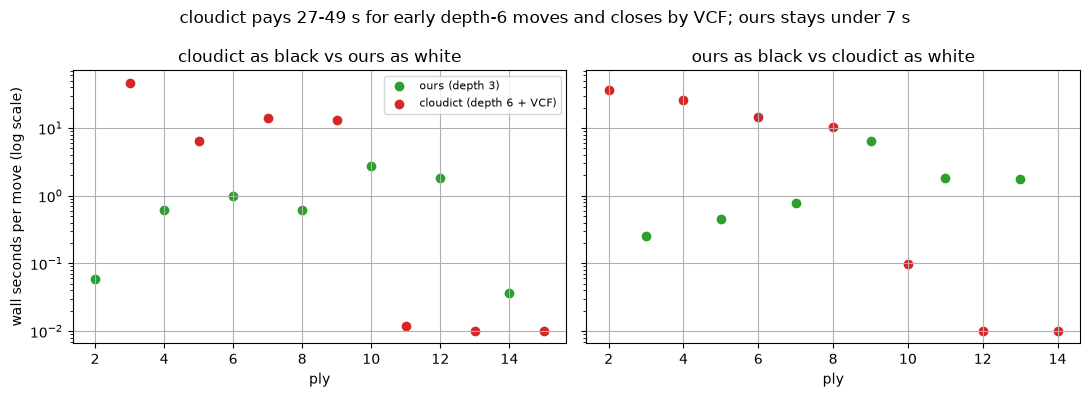

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, record in zip(axes, games):
    for tag, color in (("ours", "tab:green"), ("cloudict", "tab:red")):
        recs = [m for m in record["moves"] if m["engine"] == tag and m["ply"] > 1]
        ax.scatter([m["ply"] for m in recs], [max(m["wall"], 0.01) for m in recs],
                   color=color, label="ours (depth 3)" if tag == "ours" else "cloudict (depth 6 + VCF)")
    ax.set_yscale("log")
    ax.set_title(f"{record['black']} as black vs {record['white']} as white")
    ax.set_xlabel("ply")
    ax.grid(True)
axes[0].set_ylabel("wall seconds per move (log scale)")
axes[0].legend(fontsize=8)
fig.suptitle("cloudict pays 27-49 s for early depth-6 moves and closes by VCF; ours stays under 7 s")
plt.tight_layout()
plt.show()

## Reading the results

- **The verdict** — cloudict wins both color assignments, in 14-15 plies. Against a
  Computer-Olympiad gold medalist the deployed coursework engine loses honestly; that is
  what an external yardstick is for.
- **The VCF module is the visible gap** — from ply 10-11 cloudict's dedicated threat search
  announces the forced win and finishes both games in milliseconds. Our engine has no
  dedicated forced-win search (a documented limitation, section 7); quiescence prices
  threats within the horizon, but at depth 3 it cannot substitute for a searcher that
  follows forcing lines to the end regardless of depth.
- **Depth is the other half of the gap** — cloudict's early moves search 480,000-600,000
  nodes at depth 6, three plies deeper than our deployment depth. Our 11-1 record against
  our own plain alpha-beta (section 10) shows what quiescence buys at fixed depth; it does
  not close a horizon gap against an engine that also holds a VCF searcher.
- **The book bought exactly one move** — game 1's IIKK reply came from the book; cloudict's
  next move (LJJH) left the recorded lines, and in game 2 its opening reply (IJJI) was
  never in the book's five self-play openings. A self-play book is an opening dictionary,
  not an opponent model.
- **The price profile is ours to keep** — ~0.25-7 s and at most ~19,000 nodes per move,
  30-60x cheaper than cloudict's depth-6 trees: the same cost discipline the internal
  benchmarks measure, now against an engine that spends it very differently.
- Full discussion: docs/EVALUATION.md, section 12.